# 6 · Version 1 contre le DE séquentiel : qualité et premier speedup

Avant d'optimiser, nous avons vérifié que la version GPU donne la même qualité que le DE séquentiel, puis
mesuré le gain de temps. Les deux programmes tournent sur la même machine Colab (CPU Xeon, GPU T4), avec
la même interface et le même budget. Nous comparons 10 runs de chaque programme avec un test de
Mann-Whitney (si p > 0,05, on ne peut pas distinguer les deux séries d'erreurs), d'abord sur Sphere et
Rastrigin en D = 10, puis sur deux cas plus difficiles où l'erreur finale n'est pas nulle. Nous mesurons
enfin le speedup (temps séquentiel / temps GPU) sur les 4 fonctions pour D = 10, 50 et 100.

In [1]:
# Récupérer le projet.
# Si DE_CUDA.zip a été déposé dans Colab (icône dossier à gauche → Importer), on utilise ce dossier ;
# sinon on copie le dépôt public GitHub (aucun compte nécessaire).
import os
if os.path.exists("/content/DE_CUDA.zip") and not os.path.exists("/content/DE_CUDA/src"):
    !unzip -q -o /content/DE_CUDA.zip -d /content
if not os.path.exists("/content/DE_CUDA/src"):
    !git clone -q https://github.com/amenacer/DE_CUDA.git /content/DE_CUDA
%cd /content/DE_CUDA
!nvidia-smi --query-gpu=name,driver_version,memory.total --format=csv

/content/DE_CUDA
name, driver_version, memory.total [MiB]
Tesla T4, 580.82.07, 15360 MiB


In [2]:
import subprocess, re, statistics as st, os, json
ROOT = "/content/DE_CUDA"
RAPPORT = []                       # tout ce qui est affiche est aussi garde pour le rapport
def note(s=""):
    print(s); RAPPORT.append(str(s))

def run(args, cwd=ROOT, ok_codes=(0,)):
    p = subprocess.run(args, cwd=cwd, capture_output=True, text=True)
    if p.returncode not in ok_codes:
        print(p.stdout); print(p.stderr)
        raise RuntimeError(f"{args[0]} a renvoye {p.returncode}")
    return p

def compile_cuda(src, out):
    p = run(["nvcc", "-O3", "-arch=sm_75", "-Xcompiler", "-Wall", "-Xcompiler", "-Wextra",
             "-o", out, src], cwd=f"{ROOT}/src/cuda")
    warn = (p.stdout + p.stderr).strip()
    note(f"{src} : " + ("compilation SANS aucun warning" if not warn else "WARNINGS :\n" + warn))

KV = re.compile(r"(\w+)=(\S+)")
def lance(prog, f, D, N, seed, csv=None, extra=()):
    """Lance un run et renvoie le dictionnaire de sa derniere ligne (best_error, time_s, ...)."""
    args = [prog, f, str(D), str(N), str(seed)] + ([csv] if csv else []) + list(extra)
    out = run(args).stdout.strip().splitlines()[-1]
    d = dict(KV.findall(out))
    for k in ("best_error", "time_s"):
        d[k] = float(d[k])
    return d

def mann_whitney(a, b):
    """p-valeur du test de Mann-Whitney bilateral ; 1.0 si les deux series sont identiques et constantes."""
    from scipy.stats import mannwhitneyu
    if len(set(a) | set(b)) == 1:
        return 1.0
    return float(mannwhitneyu(a, b, alternative="two-sided").pvalue)

def tableau_md(lignes, entetes):
    s = "| " + " | ".join(entetes) + " |\n|" + "---|" * len(entetes) + "\n"
    for l in lignes:
        s += "| " + " | ".join(str(x) for x in l) + " |\n"
    return s
print("outils prets")

outils prets


## 1. Compiler les deux programmes

In [3]:
run(["g++", "-std=c++14", "-O2", "-o", "sde", "sde.cpp"], cwd=f"{ROOT}/src/seq")
compile_cuda("de_cuda_v1.cu", "de_cuda_v1")
SDE, V1 = f"{ROOT}/src/seq/sde", f"{ROOT}/src/cuda/de_cuda_v1"
note("CPU : " + run(["bash", "-c", "lscpu | grep 'Model name' | sed 's/Model name: *//'"]).stdout.strip())

de_cuda_v1.cu : compilation SANS aucun warning
CPU : Intel(R) Xeon(R) CPU @ 2.00GHz


## 2. Validation : 10 runs CPU contre 10 runs GPU

Sphere et Rastrigin, D = 10, N = 50.

In [4]:
CSV_VAL = f"{ROOT}/results/validation_v1_vs_sde.csv"
os.makedirs(f"{ROOT}/results", exist_ok=True)
if os.path.exists(CSV_VAL): os.remove(CSV_VAL)
lignes = []
for f in ["sphere", "rastrigin"]:
    e = {"sde": [], "cuda_v1": []}
    for seed in range(1, 11):
        e["sde"].append(lance(SDE, f, 10, 50, seed, CSV_VAL)["best_error"])
        e["cuda_v1"].append(lance(V1, f, 10, 50, seed, CSV_VAL)["best_error"])
    p = mann_whitney(e["sde"], e["cuda_v1"])
    for algo in ("sde", "cuda_v1"):
        v = e[algo]
        lignes.append([f, algo, f"{st.mean(v):.3e}", f"{st.pstdev(v):.3e}", f"{st.median(v):.3e}",
                       f"{min(v):.3e}", f"{max(v):.3e}", f"{p:.3f}" if algo == "cuda_v1" else "",
                       ("p > 0,05 : pas de difference" if p > 0.05 else "p <= 0,05 : difference") if algo == "cuda_v1" else ""])
note("Validation D = 10, N = 50, 10 runs (erreur finale f(x) - f(x*))")
note(tableau_md(lignes, ["fonction", "algo", "moyenne", "ecart-type", "mediane", "min", "max", "p (Mann-Whitney)", "conclusion"]))

Validation D = 10, N = 50, 10 runs (erreur finale f(x) - f(x*))
| fonction | algo | moyenne | ecart-type | mediane | min | max | p (Mann-Whitney) | conclusion |
|---|---|---|---|---|---|---|---|---|
| sphere | sde | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 |  |  |
| sphere | cuda_v1 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 1.000 | p > 0,05 : pas de difference |
| rastrigin | sde | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 |  |  |
| rastrigin | cuda_v1 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 0.000e+00 | 1.000 | p > 0,05 : pas de difference |



## 3. Validation complémentaire

En D = 10, Sphere et Rastrigin sont résolues exactement (erreur 0) par les deux programmes : le test compare deux séries de zéros et ne peut rien détecter. On ajoute deux cas où l'erreur finale n'est pas nulle : **Rosenbrock D = 10** et **Rastrigin D = 50** (N = 50, 10 runs).

À noter : le séquentiel remplace un individu **dès** que son essai est meilleur (les individus suivants de la même génération voient déjà la nouvelle valeur), alors que le GPU remplace **en fin de génération** (obligatoire en parallèle). Une différence de qualité peut venir de là, pas d'une erreur de programmation.

In [5]:
CSV_VAL2 = f"{ROOT}/results/validation_v1_vs_sde_complement.csv"
if os.path.exists(CSV_VAL2): os.remove(CSV_VAL2)
lignes = []
for f, D in (("rosenbrock", 10), ("rastrigin", 50)):
    e = {"sde": [], "cuda_v1": []}
    for seed in range(1, 11):
        e["sde"].append(lance(SDE, f, D, 50, seed, CSV_VAL2)["best_error"])
        e["cuda_v1"].append(lance(V1, f, D, 50, seed, CSV_VAL2)["best_error"])
    p = mann_whitney(e["sde"], e["cuda_v1"])
    lignes.append([f, D, f"{st.mean(e['sde']):.3e} ± {st.pstdev(e['sde']):.2e}", f"{st.median(e['sde']):.3e}",
                   f"{st.mean(e['cuda_v1']):.3e} ± {st.pstdev(e['cuda_v1']):.2e}", f"{st.median(e['cuda_v1']):.3e}",
                   f"{p:.3f}", "pas de difference" if p > 0.05 else "difference significative"])
note("Validation complementaire (N = 50, 10 runs)")
note(tableau_md(lignes, ["fonction", "D", "sde moyenne ± ET", "sde mediane", "GPU v1 moyenne ± ET", "GPU v1 mediane", "p (Mann-Whitney)", "conclusion (5 %)"]))

Validation complementaire (N = 50, 10 runs)
| fonction | D | sde moyenne ± ET | sde mediane | GPU v1 moyenne ± ET | GPU v1 mediane | p (Mann-Whitney) | conclusion (5 %) |
|---|---|---|---|---|---|---|---|
| rosenbrock | 10 | 2.033e+00 ± 1.62e+00 | 2.036e+00 | 7.206e-01 ± 1.05e+00 | 1.040e-01 | 0.089 | pas de difference |
| rastrigin | 50 | 1.514e+02 ± 6.55e+00 | 1.516e+02 | 1.456e+02 ± 6.56e+00 | 1.459e+02 | 0.140 | pas de difference |



## 4. Speedup : D = 10, 50, 100 avec N = 100

4 fonctions, 5 runs chacun ; speedup = temps séquentiel / temps GPU.

In [6]:
CSV_SP = f"{ROOT}/results/speedup_v1.csv"
if os.path.exists(CSV_SP): os.remove(CSV_SP)
SP = {}
lignes = []
for f in ["sphere", "rosenbrock", "griewank", "rastrigin"]:
    for D in (10, 50, 100):
        tc = [lance(SDE, f, D, 100, s, CSV_SP)["time_s"] for s in range(1, 6)]
        tg = [lance(V1, f, D, 100, s, CSV_SP)["time_s"] for s in range(1, 6)]
        sp = st.mean(tc) / st.mean(tg)
        SP[(f, D)] = sp
        lignes.append([f, D, f"{st.mean(tc):.4f} ± {st.pstdev(tc):.4f}", f"{st.mean(tg):.4f} ± {st.pstdev(tg):.4f}", f"{sp:.2f}"])
note("Speedup du DE GPU v1 (N = 100, temps moyen sur 5 runs, en secondes)")
note(tableau_md(lignes, ["fonction", "D", "sequentiel (s)", "GPU v1 (s)", "speedup"]))

Speedup du DE GPU v1 (N = 100, temps moyen sur 5 runs, en secondes)
| fonction | D | sequentiel (s) | GPU v1 (s) | speedup |
|---|---|---|---|---|
| sphere | 10 | 0.0232 ± 0.0008 | 0.0158 ± 0.0002 | 1.47 |
| sphere | 50 | 0.4579 ± 0.0067 | 0.2734 ± 0.0402 | 1.68 |
| sphere | 100 | 1.7678 ± 0.0327 | 0.8765 ± 0.0198 | 2.02 |
| rosenbrock | 10 | 0.0219 ± 0.0003 | 0.0181 ± 0.0000 | 1.21 |
| rosenbrock | 50 | 0.4714 ± 0.0041 | 0.3422 ± 0.0499 | 1.38 |
| rosenbrock | 100 | 1.8559 ± 0.0238 | 1.1777 ± 0.0329 | 1.58 |
| griewank | 10 | 0.0406 ± 0.0020 | 0.0361 ± 0.0001 | 1.12 |
| griewank | 50 | 0.8767 ± 0.2283 | 0.7840 ± 0.0604 | 1.12 |
| griewank | 100 | 3.0666 ± 0.0347 | 2.8982 ± 0.0192 | 1.06 |
| rastrigin | 10 | 0.0347 ± 0.0028 | 0.0261 ± 0.0001 | 1.33 |
| rastrigin | 50 | 0.9571 ± 0.0178 | 0.5080 ± 0.0507 | 1.88 |
| rastrigin | 100 | 3.9206 ± 0.1222 | 1.8687 ± 0.0575 | 2.10 |



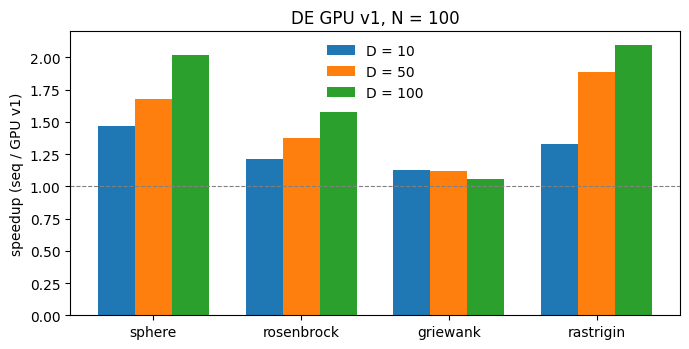

In [7]:
import matplotlib.pyplot as plt, numpy as np
os.makedirs(f"{ROOT}/figures", exist_ok=True)
fs = ["sphere", "rosenbrock", "griewank", "rastrigin"]; Ds = [10, 50, 100]
x = np.arange(len(fs)); w = 0.25
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, D in enumerate(Ds):
    ax.bar(x + (k - 1) * w, [SP[(f, D)] for f in fs], w, label=f"D = {D}")
ax.axhline(1, color="gray", lw=0.8, ls="--")
ax.set_xticks(x, fs); ax.set_ylabel("speedup (seq / GPU v1)"); ax.set_title("DE GPU v1, N = 100")
ax.legend(frameon=False); fig.tight_layout()
fig.savefig(f"{ROOT}/figures/speedup_v1.png", dpi=200); plt.show()

## 5. Rapport

La dernière cellule enregistre les résultats ci-dessus dans `results/etape3_validation_speedup.md`.

In [8]:
os.makedirs(f"{ROOT}/results", exist_ok=True)
with open(f"{ROOT}/results/etape3_validation_speedup.md", "w") as fp:
    fp.write("# Étape 3.6-3.7 — validation du GPU contre le séquentiel et speedup\n\n")
    fp.write("GPU : " + run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"]).stdout.strip() + "\n\n")
    fp.write("```\n" + "\n".join(RAPPORT) + "\n```\n")